<a href="https://colab.research.google.com/github/polina5544/Chemistry/blob/master/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22Untitled5_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab01 - sprint 1


В нашей лабораторной работе используется экспериментальный датасет спектров комбинационного рассеяния света (Raman spectroscopy), полученный для водных растворов сахаров.

Данные взяты из открытого репозитория Raman_Sugars на GitHub (https://github.com/Alvaro-FG/Raman_Sugars)

Полный спектр содержит множество значений интенсивности. Чтобы лабораторная была обозримой, мы выбрали три рамановских сдвига и для каждого спектра извлекли интенсивность в ближайшей доступной точке. Так мы исследовали 3 величины, а именно длина волна 500, 1000, 1400 см-1.

В результате у нас получилась таблица из 1960 строк и трёх исследуемых величин. К каждой строке также присоединены метаданные, поэтому мы знаем, какому составу соответствует измерение.

## Random Variables: Raman Spectral Intensities

### Description (природа события)

При повторных измерениях одного и того же состава интенсивности могут различаться из-за погрешности лабораторного прибора (спектрофотометра), из за человеческого фактора, так как люди сколонны совершать ошибки в точных измерениях (при подготовке пробы, при настройке прибора). При разных измерениях температура в комнате может быть разной, образец может быть загрязнен.Так же величина случайна, так как состав раствора разный, это влияет напрямую на интенсивность, поэтому мы исследуем как различия между составами, так и вариации между повторами.

Проанализируем структуру таблицы и решим какие взять случайные величины:

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

base_url = (
    "https://raw.githubusercontent.com/"
    "Alvaro-FG/Raman_Sugars/main/"
)

spectra = pd.read_csv(
    base_url + "Sugar_Concentration_Test_ALL_spectra.csv"
)

metadata = pd.read_csv(
    base_url + "Sugar_Concentration_Test_ALL_metadata.csv"
)

print("Размер таблицы спектров:", spectra.shape)
print("Размер таблицы метаданных:", metadata.shape)

print("\nСтолбцы метаданных:")
print(metadata.columns.tolist())

print("\nПервые строки метаданных:")
print(metadata.head())

print("\nПервые строки спектров:")
print(spectra.iloc[:5, :5])


Размер таблицы спектров: (2000, 1961)
Размер таблицы метаданных: (1960, 14)

Столбцы метаданных:
['samp', 'row', 'col', 'plate', 'round', 'meas', 'rep', 'filename', 'Sucrose [ul]', 'Fructose [ul]', 'Maltose [ul]', 'Glucose [ul]', 'Water [ul]', 'Total Volume [ul]']

Первые строки метаданных:
   samp row  col  plate  round  meas  rep  \
0    54   E    6      2      2     1    1   
1    43   D    7      3      2     1    2   
2    35   C   11      2      2     1    4   
3    10   A   10      1      1     1    3   
4    94   H   10      1      2     1    1   

                                      filename  Sucrose [ul]  Fructose [ul]  \
0   Sugar_Concentration_Test_54_E6_2_RD2_M1_R1            30             30   
1   Sugar_Concentration_Test_43_D7_3_RD2_M1_R2             0              0   
2  Sugar_Concentration_Test_35_C11_2_RD2_M1_R4            30             75   
3  Sugar_Concentration_Test_10_A10_1_RD1_M1_R3           120            120   
4  Sugar_Concentration_Test_94_H10_1_RD2_M

Проверим, есть ли целевые частоты на самом деле, и если нет, то возьмем ближайшее к ним значение :

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Частоты спектра
wavenumbers = spectra["Wavenumber [cm-1]"].to_numpy()

# Ищем ближайшую измеренную частоту к каждой целевой
targets = [500, 1000, 1400]
selected_indices = [
    np.abs(wavenumbers - target).argmin()
    for target in targets
]

for target, idx in zip(targets, selected_indices):
    print(
        f"Целевая частота: {target} см⁻¹; "
        f"фактическая: {wavenumbers[idx]:.2f} см⁻¹"
    )

Целевая частота: 500 см⁻¹; фактическая: 500.33 см⁻¹
Целевая частота: 1000 см⁻¹; фактическая: 998.80 см⁻¹
Целевая частота: 1400 см⁻¹; фактическая: 1399.34 см⁻¹


 Получаем интенсивности на трех выбранных частотах (для наглядности мы выводим только 9 строк, на самом же деле их очевидно, что гораздо больше):

In [ ]:
X = spectra.iloc[selected_indices, 1:].T.copy()

X.columns = ["X1", "X2", "X3"]
X = X.reset_index(drop=True)

# Добавляем метаданные: состав смеси и номер повторения
data = pd.concat(
    [metadata.reset_index(drop=True), X],
    axis=1
)

print("Размер итоговой таблицы:", data.shape)
print("\nПервые строки:")
print(data[[
    "Sucrose [ul]", "Fructose [ul]",
    "Maltose [ul]", "Glucose [ul]",
    "X1", "X2", "X3"
]].head(9))

print("\nОписательная статистика:")
print(data[["X1", "X2", "X3"]].describe().round(2))


Размер итоговой таблицы: (1960, 17)

Первые строки:
   Sucrose [ul]  Fructose [ul]  Maltose [ul]  Glucose [ul]      X1      X2  \
0            30             30            75           120  3951.0  1693.0   
1             0              0            30            75  3120.0  1452.0   
2            30             75           120            75  3994.0  1760.0   
3           120            120             0             0  3505.0  1657.0   
4            75             30            30             0  2999.0  1456.0   
5             0             30            75            75  3439.0  1586.0   
6            75              0            75           120  4170.0  1799.0   
7             0            120           120           120  4240.0  1775.0   
8            30             75            75             0  3253.0  1568.0   

       X3  
0  1579.0  
1  1225.0  
2  1823.0  
3  1544.0  
4  1349.0  
5  1520.0  
6  1713.0  
7  1784.0  
8  1486.0  

Описательная статистика:
            X1       

У нас 3 величины имеют одну природу события, исследуем их на зависимость(независимость)

Сначала посмторим на корреляцию Пирсона - показывает, насколько точки данных ложатся на прямую линию. Учитывает отклонения каждого значения от среднего арифметического. Если данные распределены неправильно или есть выбросы, результат будет нелинейный.

In [ ]:
print("Корреляция Пирсона:")
print(data[["X1", "X2", "X3"]].corr().round(3))

Корреляция Пирсона:
       X1     X2     X3
X1  1.000  0.885  0.877
X2  0.885  1.000  0.963
X3  0.877  0.963  1.000


Пирсон показал, что величины неплохо коррелируют, значит гипотетически они могут быть зависимы. Проверим для надежности корреляцию Спирмена - это нужно, в случае если наши данные растут не по прямой линии, а скачками или по логарифму.

In [ ]:
spearman_corr = data[variables].corr(method="spearman")

print("\nКорреляция Спирмена:")
print(spearman_corr.round(3))


Корреляция Спирмена:
       X1     X2     X3
X1  1.000  0.891  0.885
X2  0.891  1.000  0.965
X3  0.885  0.965  1.000


Результат повторился, все три пары имеют сильную положительную связь. Особенно высокая связь наблюдается между X2 и X3.
Но пока это корреляции исходных интенсивностей, объединённых по всем составам растворов. Но у нас разные смеси сахаров. Их состав различается, и это может влиять сразу на обе интенсивности, по этому мы приняли решение исследовать это отдельно и выяснить, связаны ли отклонения интенсивностей на разных частотах при фиксированном составе смеси? Для этого мы рассчитываем корреляцию между отклонениями.

In [ ]:
sugar_columns = [
    "Sucrose [ul]",
    "Fructose [ul]",
    "Maltose [ul]",
    "Glucose [ul]",
    "Water [ul]"
]

variables = ["X1", "X2", "X3"]

# Средняя интенсивность для каждого состава
composition_means = data.groupby(
    sugar_columns
)[variables].transform("mean")

# Отклонения каждого измерения от среднего своего состава
residuals = data[variables] - composition_means

print("Корреляция отклонений от среднего состава:")
print(residuals.corr().round(3))

print("\nСтандартные отклонения исходных интенсивностей:")
print(data[variables].std().round(2))

print("\nСтандартные отклонения отклонений внутри состава:")
print(residuals.std().round(2))


Корреляция отклонений от среднего состава:
       X1     X2     X3
X1  1.000  0.077  0.050
X2  0.077  1.000  0.068
X3  0.050  0.068  1.000

Стандартные отклонения исходных интенсивностей:
X1    428.90
X2    148.83
X3    233.30
dtype: float64

Стандартные отклонения отклонений внутри состава:
X1    46.05
X2    26.50
X3    35.56
dtype: float64


Все коэффициенты близки к нулю.
Это означает, что после учёта состава раствора мы не обнаружили выраженной линейной связи между отклонениями интенсивностей. Таким образом, можно сделать вывод, что величны имеют одинаковую природу собития, однако являются независимыми,если учитывать состав растовара.

## Random Variable 01 (X1 - интенсивность на длине волны 500.33 cm⁻¹)

Определим для величины 1 состоятельность оценок

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X1 = data["X1"]

# Характеристики всех 1960 измерений - ориентиры
true_mean = X1.mean()
true_variance = X1.var(ddof=1)

print(f"Среднее по всем данным: {true_mean:.2f}")
print(f"Дисперсия по всем данным: {true_variance:.2f}")

# Размеры выборок
sample_sizes = [20, 50, 100, 300, 600, 1000]
n_repeats = 500

rng = np.random.default_rng(42)
results = []

# Многократный случайный отбор без возвращения
for n in sample_sizes:
    for _ in range(n_repeats):
        sample = X1.sample(
            n=n,
            replace=False,
            random_state=int(rng.integers(0, 2**31))
        )

        results.append({
            "n": n,
            "mean": sample.mean(),
            "variance": sample.var(ddof=1)
        })

results = pd.DataFrame(results)

summary = results.groupby("n").agg(
    mean_estimate=("mean", "mean"),
    mean_sd=("mean", "std"),
    variance_estimate=("variance", "mean"),
    variance_sd=("variance", "std")
)

print("\nРезультаты:")
print(summary.round(2))

Среднее по всем данным: 3550.86
Дисперсия по всем данным: 183956.79

Результаты:
      mean_estimate  mean_sd  variance_estimate  variance_sd
n                                                           
20          3548.50    93.33          184096.51     54367.38
50          3552.76    60.33          187110.21     33687.18
100         3548.89    40.66          182667.17     23053.28
300         3550.71    21.87          183189.03     12322.17
600         3551.49    15.28          183631.52      8576.39
1000        3551.23     9.43          183958.95      4966.56


При увеличении объема выборки с 20 до 1000 стандартное отклонение оценки выборочного среднего уменьшилось с 93,33 до 9,43, а стандартное отклонение оценки дисперсии - с 54367,38 до 4966,56. Средние значения оценок оставались близкими к значениям, рассчитанным по исходному и полному набору данных.

Так обе оценки становятся более стабильными по мере увеличения объема выборки, что очевидно было ожидаемо.

Построим 2 графика - для среднего и для дисперсии

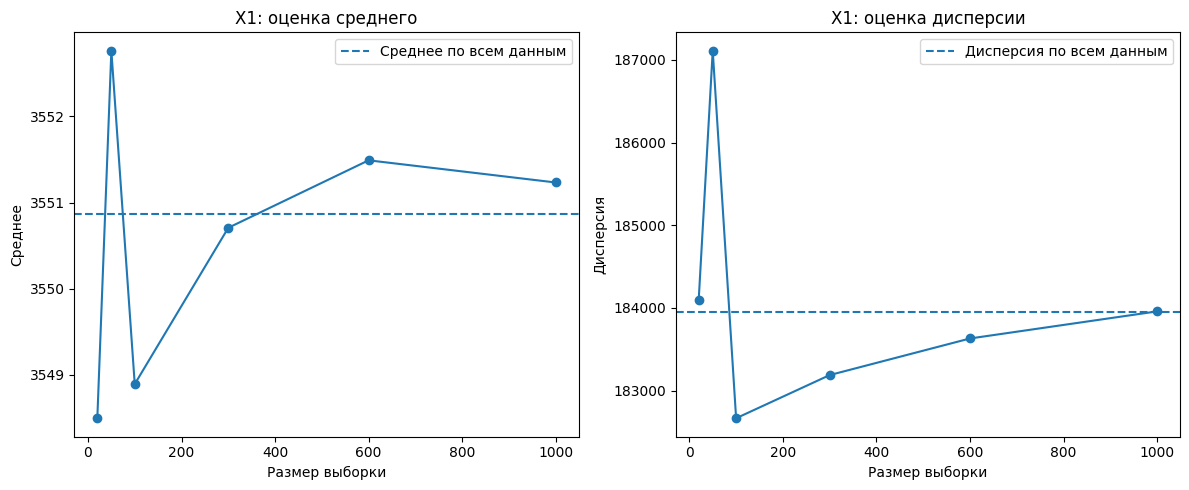

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Среднее
axes[0].plot(
    summary.index,
    summary["mean_estimate"],
    marker="o"
)
axes[0].axhline(
    true_mean,
    linestyle="--",
    label="Среднее по всем данным"
)
axes[0].set_title("X1: оценка среднего")
axes[0].set_xlabel("Размер выборки")
axes[0].set_ylabel("Среднее")
axes[0].legend()

# Дисперсия
axes[1].plot(
    summary.index,
    summary["variance_estimate"],
    marker="o"
)
axes[1].axhline(
    true_variance,
    linestyle="--",
    label="Дисперсия по всем данным"
)
axes[1].set_title("X1: оценка дисперсии")
axes[1].set_xlabel("Размер выборки")
axes[1].set_ylabel("Дисперсия")
axes[1].legend()

plt.tight_layout()
plt.show()